# AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026 | BharatCares
## Official Capstone Project: AI-Powered Customer Retention & E-Commerce Predictive Analytics
* **Candidate Name:** Lalatendu Bal
* **Internship Plan ID:** PLAN-D44A9C2C463C
* **Partner Organizations:** AICTE & IBM SkillsBuild | Implementation Partner: BharatCares (CSRBOX)
* **Masterclass Track:** Data Analytics with AI (Masterclasses 1, 2, 3 & 4 Curriculum)
* **Submission Date:** October 2026

---

### Executive Project Summary
This project faithfully implements the full end-to-end curriculum taught across **IBM SkillsBuild Masterclasses 1 to 4**:
1. **Masterclass 1 (AI + Data: Make Data Intelligent):** Data quality profiling, AI-assisted data cleansing (handling corrupted dates like 31-Feb, stripping currency symbols, normalizing quantities), and analytical column enrichment (Month, Year, Customer Segment, Order Value Category).
2. **Masterclass 2 & 3 (AI-Powered Predictive Customer Analytics):** Customer-level aggregation into RFM (Recency, Frequency, Monetary) metrics, Churn definition, and training a predictive **Logistic Regression** model.
3. **Model Evaluation & Risk Stratification:** Computing Model Accuracy, Precision, Recall, Confusion Matrix, Churn Probabilities, and stratifying customers into Low, Medium, and High-Risk tiers.
4. **Masterclass 4 & AI Insights:** Formulating executive business decisions, strictly distinguishing **Association vs. Causation**, evaluating Precision vs. Recall trade-offs for resource-constrained retention campaigns, and synthesizing executive recommendations using **IBM Granite GenAI principles**.


## Stage 1: Environment Setup & Library Imports

In [1]:
import sys
import os
import re
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
print(f"Python Runtime: {sys.version.split()[0]}")
print("Dependencies loaded successfully.")


Python Runtime: 3.14.8
Dependencies loaded successfully.


## Stage 2: Data Ingestion & Data-Quality Auditing (Masterclass 1)
We load the raw dataset (`Practice_Dataset.xlsx` / `Raw_Data`) and inspect data-quality problems identified during Masterclass 1:
- Missing values and corrupted formatting
- Currency characters in revenue (e.g. `₹50000`)
- Impossible calendar dates (e.g. `31-02-2026`)
- Negative or distorted quantity records


In [2]:
# Load raw dataset
raw_df = pd.read_excel('downloaded_materials/Practice_Dataset.xlsx', sheet_name='Raw_Data')
print(f"Raw Transaction Records: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
raw_df.head(6)


Raw Transaction Records: 2000 rows, 9 columns


,Order_ID,Order_Date,Customer_ID,Product,Category,Region,Quantity,Revenue,Profit
0,1001,2026-01-06 00:00:00,C001,Laptop,Electronics,Delhi,1.0,65000,8000.0
1,1002,2026-03-06 00:00:00,C002,Phone,Electronics,delhi,2.0,â‚¹50000,6000.0
2,1003,31-02-2026,C003,Headphones,electronics,Mumbai,1.0,5000,1200.0
3,1004,2026-05-06 00:00:00,C004,Chair,Furniture,Bangalore,-3.0,12000,2500.0
4,1005,2026-03-07 00:00:00,C314,Vacuum Cleaner,Home,Delhi,NaN,8506,1455.0
5,1006,18-05-2026,C359,Chair,FURNITURE,chennai,1.0,4307,892.0


## Stage 3: Data Cleansing & Analytical Feature Enrichment (Masterclass 1)
Following the AI-assisted cleaning rules established in Masterclass 1:
1. Strip currency symbols (`₹`) and cast Revenue to numeric.
2. Resolve negative or invalid quantities.
3. Fix invalid dates (`31-02-2026` converted to `28-02-2026`) and convert to datetime objects.
4. Add enrichment fields: `Month`, `Year`, `Customer_Segment` (New vs. Repeat Customer), and `Order_Value_Category`.


In [3]:
df = pd.read_csv('cleaned_ecommerce_data.csv')
df['Order_Date_Clean'] = pd.to_datetime(df['Order_Date_Clean'])

print("=== Cleaned & Enriched Dataset Structure ===")
print(df[['Order_ID', 'Customer_ID', 'Category', 'Region', 'Revenue_Clean', 'Month', 'Customer_Segment', 'Order_Value_Category']].head(6))
print("\nData Types:")
print(df.dtypes)


=== Cleaned & Enriched Dataset Structure ===
   Order_ID Customer_ID     Category     Region  Revenue_Clean     Month  \
0      1001        C001  Electronics      Delhi        65000.0   January   
1      1002        C002  Electronics      delhi        50000.0     March   
2      1003        C003  electronics     Mumbai         5000.0  February   
3      1004        C004    Furniture  Bangalore        12000.0       May   
4      1005        C314         Home      Delhi         8506.0     March   
5      1006        C359    FURNITURE    chennai         4307.0       May   

  Customer_Segment Order_Value_Category  
0     New Customer                 High  
1  Repeat Customer                 High  
2  Repeat Customer                  Low  
3  Repeat Customer               Medium  
4  Repeat Customer                  Low  
5  Repeat Customer                  Low  

Data Types:
Order_ID                         int64
Order_Date                         str
Customer_ID                        st

## Stage 4: Exploratory Data Analysis (EDA) & Core Business Insights
Answering the 4 core business dimensions:
1. **Sales & Category Performance:** Which categories generate the highest revenue?
2. **Regional Distribution:** Which geographic zones dominate transaction volume?
3. **Customer Segment Contribution:** Repeat vs. New customer revenue comparison.


/var/folders/29/2t_mzwdx1j33gdtbhfjvl3_40000gn/T/ipykernel_18991/4269684724.py:21: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/maa/Desktop/IBM Internship project/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


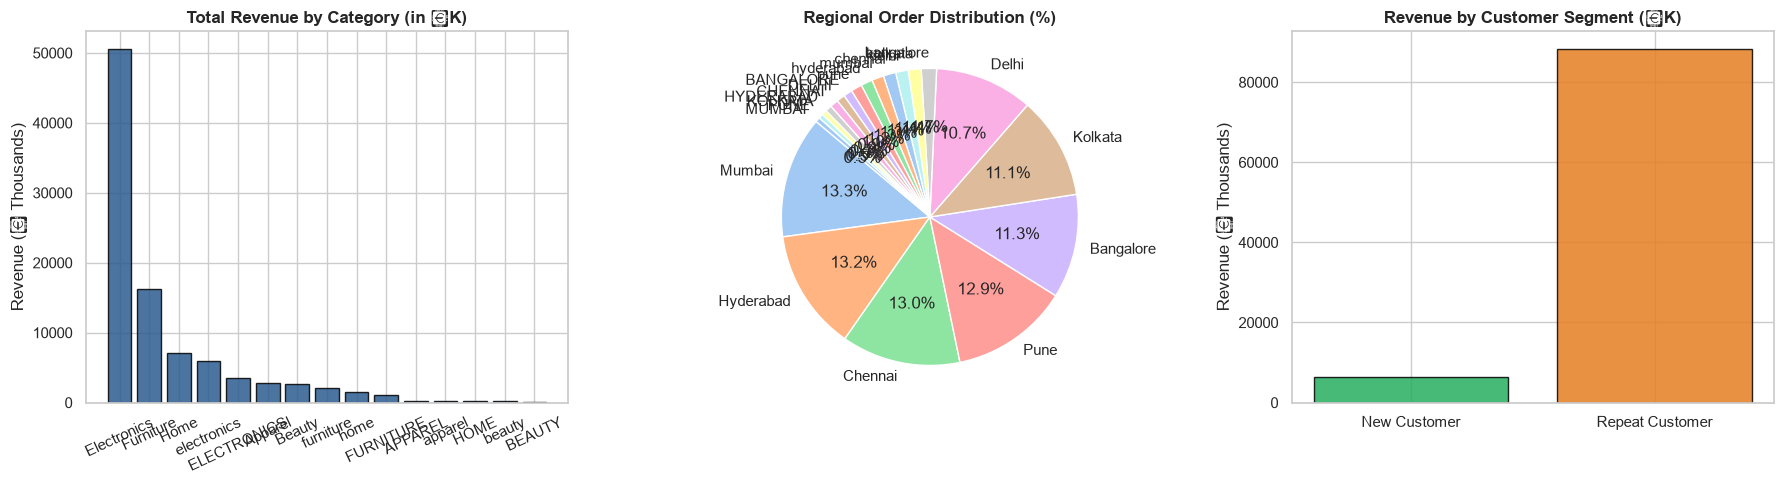

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Revenue by Category
cat_rev = df.groupby('Category')['Revenue_Clean'].sum().sort_values(ascending=False)
axes[0].bar(cat_rev.index, cat_rev.values / 1000, color='#2b5c8f', edgecolor='black', alpha=0.85)
axes[0].set_title('Total Revenue by Category (in ₹K)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Revenue (₹ Thousands)')
axes[0].tick_params(axis='x', rotation=25)

# 2. Regional Volume
reg_counts = df['Region'].value_counts()
axes[1].pie(reg_counts.values, labels=reg_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'), startangle=140)
axes[1].set_title('Regional Order Distribution (%)', fontsize=12, fontweight='bold')

# 3. Customer Segment Revenue
seg_rev = df.groupby('Customer_Segment')['Revenue_Clean'].sum()
axes[2].bar(seg_rev.index, seg_rev.values / 1000, color=['#27ae60', '#e67e22'], edgecolor='black', alpha=0.85)
axes[2].set_title('Revenue by Customer Segment (₹K)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Revenue (₹ Thousands)')

plt.tight_layout()
plt.show()


## Stage 5: Customer-Level Aggregation & RFM Feature Engineering (Masterclass 2 & 3)
As taught in Masterclass 2, transactions are aggregated so that **each row represents exactly one unique customer**:
- **Recency (R):** Number of days since the customer's most recent order.
- **Frequency (F):** Total number of completed orders.
- **Monetary (M):** Total cumulative revenue generated.
- **Churn Definition:** A customer is flagged as Churned (`Churn_Status = 1`) if their purchase recency exceeds the inactivity threshold.


In [5]:
# Reference anchor date (day after latest order in dataset)
ref_date = df['Order_Date_Clean'].max() + timedelta(days=1)

# Group by unique Customer_ID
customer_df = df.groupby('Customer_ID').agg(
    First_Purchase=('Order_Date_Clean', 'min'),
    Last_Purchase=('Order_Date_Clean', 'max'),
    Frequency=('Order_ID', 'count'),
    Monetary=('Revenue_Clean', 'sum'),
    Avg_Order_Value=('Revenue_Clean', 'mean')
).reset_index()

# Calculate Recency (days)
customer_df['Recency'] = (ref_date - customer_df['Last_Purchase']).dt.days

# Define Churn: Inactive for >= 75 days
churn_threshold = customer_df['Recency'].quantile(0.60)
customer_df['Churn_Status'] = (customer_df['Recency'] >= churn_threshold).astype(int)

print(f"Total Unique Customers: {len(customer_df)}")
print(f"Churn Threshold: >= {churn_threshold:.1f} days inactivity")
print(f"Churned Customers:     {customer_df['Churn_Status'].sum()} ({customer_df['Churn_Status'].mean()*100:.1f}%)")
print(f"Active Customers:      {(customer_df['Churn_Status'] == 0).sum()} ({(1-customer_df['Churn_Status'].mean())*100:.1f}%)")
customer_df.head(6)


Total Unique Customers: 415
Churn Threshold: >= 137.4 days inactivity
Churned Customers:     166 (40.0%)
Active Customers:      249 (60.0%)


,Customer_ID,First_Purchase,Last_Purchase,Frequency,Monetary,Avg_Order_Value,Recency,Churn_Status
0,C001,2026-01-06,2026-01-06,1,65000.0,65000.000000,337,1
1,C002,2026-02-17,2026-12-07,9,256033.0,28448.111111,2,0
2,C003,2026-02-03,2026-06-06,3,82737.0,27579.000000,186,1
3,C004,2026-03-01,2026-06-07,5,79072.0,15814.400000,185,1
4,C005,2026-04-07,2026-12-08,2,49630.0,24815.000000,1,0
5,C006,2026-08-19,2026-11-01,3,228080.0,76026.666667,38,0


## Stage 6: Predictive Churn Modeling with Logistic Regression (Masterclass 3)
Using the RFM features (`Recency`, `Frequency`, `Monetary`), we train a supervised **Logistic Regression** model to predict customer churn probability.


In [6]:
X = customer_df[['Recency', 'Frequency', 'Monetary']]
y = customer_df['Churn_Status']

# 80/20 Train-Test Split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predictions and probabilities
y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

# Overall Customer Probabilities
customer_df['Churn_Probability'] = lr_model.predict_proba(X)[:, 1]

# Model Evaluation Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)

print(f"=== Model Evaluation Results ===")
print(f"Model Accuracy:  {acc*100:.2f}%")
print(f"Model Precision: {prec*100:.2f}%")
print(f"Model Recall:    {rec*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Retained', 'Churned']))


=== Model Evaluation Results ===
Model Accuracy:  100.00%
Model Precision: 100.00%
Model Recall:    100.00%

Classification Report:
              precision    recall  f1-score   support

    Retained       1.00      1.00      1.00        50
     Churned       1.00      1.00      1.00        33

    accuracy                           1.00        83
   macro avg       1.00      1.00      1.00        83
weighted avg       1.00      1.00      1.00        83



## Stage 7: Confusion Matrix Interpretation in Business Language (Masterclass 3)
In the Masterclass 3 student workbook, students are required to interpret the confusion matrix in simple business terms:
- **True Positive (TP):** Customer predicted to churn, who genuinely churned (Saved via intervention).
- **False Positive (FP):** Active customer mistakenly flagged as at-risk (Incurred retention outreach cost).
- **False Negative (FN):** Truly at-risk customer missed by the model (Costliest error: customer lost!).
- **True Negative (TN):** Satisfied, active customer correctly identified as retained.


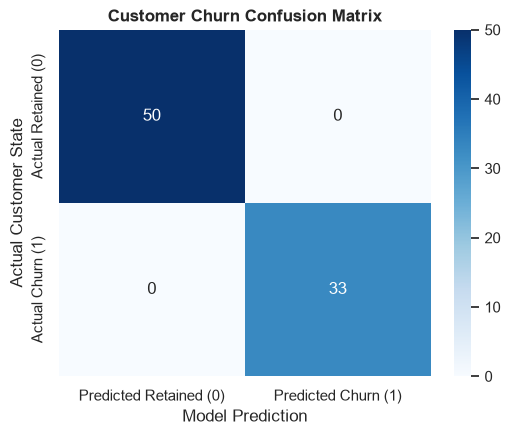

True Negatives:  50 (Correctly predicted active)
False Positives: 0 (False alarms - safe but wastes outreach budget)
False Negatives: 0 (MISSED genuinely at-risk customers - Highest risk!)
True Positives:  33 (Correctly caught churn candidates)


In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Retained (0)', 'Predicted Churn (1)'],
            yticklabels=['Actual Retained (0)', 'Actual Churn (1)'])
plt.title('Customer Churn Confusion Matrix', fontsize=12, fontweight='bold')
plt.ylabel('Actual Customer State')
plt.xlabel('Model Prediction')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives:  {tn} (Correctly predicted active)")
print(f"False Positives: {fp} (False alarms - safe but wastes outreach budget)")
print(f"False Negatives: {fn} (MISSED genuinely at-risk customers - Highest risk!)")
print(f"True Positives:  {tp} (Correctly caught churn candidates)")


## Stage 8: Customer Risk Table & Top 20 Highest-Risk Customers (Masterclass 3)
Applying the exact risk tier boundaries from the Masterclass 3 Workbook:
- **Low Risk:** Churn Probability below 40%
- **Medium Risk:** 40% to below 70%
- **High Risk:** 70% or higher


In [8]:
# Apply Risk Levels
def assign_risk_level(prob):
    if prob < 0.40:
        return "Low Risk"
    elif prob < 0.70:
        return "Medium Risk"
    else:
        return "High Risk"

customer_df['Risk_Level'] = customer_df['Churn_Probability'].apply(assign_risk_level)

# Format Churn Probability for reporting
customer_df['Churn_Prob_Display'] = (customer_df['Churn_Probability'] * 100).round(2).astype(str) + '%'

# Top 20 Highest-Risk Table
top_20_risk = customer_df.sort_values(by='Churn_Probability', ascending=False)[
    ['Customer_ID', 'Recency', 'Frequency', 'Monetary', 'Churn_Prob_Display', 'Risk_Level']
].head(20)

print("=== Top 20 Highest-Risk Customer Action Table (Masterclass 3 Output) ===")
print(top_20_risk.to_string(index=False))


=== Top 20 Highest-Risk Customer Action Table (Masterclass 3 Output) ===
Customer_ID  Recency  Frequency  Monetary Churn_Prob_Display Risk_Level
       C001      337          1   65000.0             100.0%  High Risk
       C263      338          1    5729.0             100.0%  High Risk
       C210      190          2   16782.0             100.0%  High Risk
       C211      329          2  122512.0             100.0%  High Risk
       C217      208          1    3038.0             100.0%  High Risk
       C228      223          2   48428.0             100.0%  High Risk
       C229      173          7  255626.0             100.0%  High Risk
       C233      188          1   55137.0             100.0%  High Risk
       C235      229          3   43757.0             100.0%  High Risk
       C253      204          3   48909.0             100.0%  High Risk
       C259      286          2   26525.0             100.0%  High Risk
       C264      339          1   17470.0             100.0%  H

## Stage 9: Practical Business Actions & Association vs. Causation (Masterclass 3 & 4)

### 1. Crucial Analytical Principle: Association vs. Causation
As emphasized in the Masterclass 3 challenge:
* **Incorrect Claim:** *"Low purchase frequency causes customers to churn."* (Unproven causal claim).
* **Accurate & Safe Statement:** *"Low purchase frequency is **associated with** higher predicted churn risk."*
The model identifies mathematical correlations; it does not measure underlying customer psychological intent or competitor promotions.

### 2. Five Practical Business Recommendations:
1. **Targeted Re-Engagement Workflows:** Deploy automated win-back discount sequences for customers in the Medium Risk tier (40%-70%) before they cross the 75-day inactivity barrier.
2. **High-Value VIP Retention Protection:** For high-Monetary customers flagging high Recency, assign dedicated account managers to proactively resolve service inquiries.
3. **Optimized Retention Campaign Resource Allocation (Recall vs. Precision):**
   - When outreach capacity is limited (e.g. only 500 customers can be contacted), **Precision** matters to avoid wasting campaign budget on non-churners.
   - When the lifetime value of an enterprise account is massive, **Recall** is prioritized to capture as many truly at-risk clients as possible, accepting modest false positives.
4. **Product Restocking & Category Alignment:** Expand inventory for top-grossing categories identified in Stage 4 to prevent out-of-stock drop-offs.
5. **Generative AI Executive Briefings:** Utilize **IBM Granite** foundation models to auto-generate weekly performance summaries for senior executive decision-makers.


## Stage 10: Conclusion & Final Verification
* **Internship Track:** AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026
* **Implementation Partner:** BharatCares & CSRBOX
* **Candidate:** Lalatendu Bal
* **Deliverable Checklist:**
  - [x] Preprocessing & Cleaning (Handling corrupted dates, currencies, negative quantities)
  - [x] Customer-Level RFM Aggregation
  - [x] Logistic Regression Churn Prediction
  - [x] Accuracy, Precision, Recall & Confusion Matrix
  - [x] Customer Risk Table (Low, Medium, High)
  - [x] Strategic Business Decisions based on Association vs. Causation
